In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df_2009_2010 = pd.read_excel("online_retail_II.xlsx", sheet_name="Year 2009-2010")

In [3]:
display(df_2009_2010.head(10))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [4]:
def basic_information(dataframe):
    rows,attributes = dataframe.shape
    df_dimension = dataframe.shape
    types_of_attributes = dataframe.dtypes

    return rows, attributes, df_dimension, types_of_attributes

In [5]:
basic_information(df_2009_2010)

(525461,
 8,
 (525461, 8),
 Invoice                object
 StockCode              object
 Description            object
 Quantity                int64
 InvoiceDate    datetime64[us]
 Price                 float64
 Customer ID           float64
 Country                   str
 dtype: object)

In [6]:
#drop duplicated data
df_2009_2010 = df_2009_2010.drop_duplicates()
df_2009_2010

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


In [7]:
for column in df_2009_2010.columns:
    number_of_null = df_2009_2010[column].isnull().sum()
    print(column, number_of_null)

Invoice 0
StockCode 0
Description 2928
Quantity 0
InvoiceDate 0
Price 0
Customer ID 107833
Country 0


In [8]:
CustomerID_null_percentage_2009_2010 = df_2009_2010['Customer ID'].isnull().sum() / df_2009_2010.shape[0] * 100
Description_null_percentage_2009_2010 = df_2009_2010['Description'].isnull().sum() / df_2009_2010.shape[0] * 100


print(CustomerID_null_percentage_2009_2010, Description_null_percentage_2009_2010)

20.79325717899868 0.5646013467130483


In [9]:
df_2009_2010.loc[df_2009_2010['Customer ID'].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
525231,538159,21324,NaN,-18,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525232,538158,20892,NaN,-32,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525233,538160,20956,NaN,288,2010-12-09 17:18:00,0.00,NaN,United Kingdom
525234,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom


In [10]:
df_2009_2010['Description'] = df_2009_2010['Description'].fillna("Unknown")

In [11]:
df_2009_2010.loc[df_2009_2010['Quantity'] <= 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
525231,538159,21324,Unknown,-18,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525232,538158,20892,Unknown,-32,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525234,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom
525235,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom


In [12]:
df_2009_2010['Customer ID'] = df_2009_2010['Customer ID'].fillna("Unknown")

C:\Users\Admin\AppData\Local\Temp\ipykernel_2132\3524270798.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_2009_2010['Customer ID'] = df_2009_2010['Customer ID'].fillna("Unknown")


In [13]:
df_2009_2010.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [14]:
df_2009_2010.loc[df_2009_2010['Quantity'] <= 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
525231,538159,21324,Unknown,-18,2010-12-09 17:17:00,0.00,Unknown,United Kingdom
525232,538158,20892,Unknown,-32,2010-12-09 17:17:00,0.00,Unknown,United Kingdom
525234,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,Unknown,United Kingdom
525235,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.00,Unknown,United Kingdom


In [15]:
def data_cleaning(dataframe):
    dataframe = dataframe.drop_duplicates()
    dataframe['Description'] = dataframe['Description'].fillna("Unknown")
    dataframe['Customer ID'] = dataframe['Customer ID'].fillna("Unknown")

    return dataframe

In [16]:
df_2010_2011 = pd.read_excel("online_retail_II.xlsx", sheet_name="Year 2010-2011")

In [17]:
for column in df_2010_2011.columns:
    number_of_null = df_2010_2011[column].isnull().sum()
    print(column, number_of_null)

Invoice 0
StockCode 0
Description 1454
Quantity 0
InvoiceDate 0
Price 0
Customer ID 135080
Country 0


In [18]:
CustomerID_null_percentage_2010_2011 = df_2010_2011['Customer ID'].isnull().sum() / df_2010_2011.shape[0] * 100
Description_null_percentage_2010_2011 = df_2010_2011['Description'].isnull().sum() / df_2010_2011.shape[0] * 100

print(CustomerID_null_percentage_2010_2011, Description_null_percentage_2010_2011)

24.92664833643963 0.26831023601705084


In [19]:
df_2010_2011 = data_cleaning(df_2010_2011)
df_2010_2011

C:\Users\Admin\AppData\Local\Temp\ipykernel_2132\3615470755.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  dataframe['Customer ID'] = dataframe['Customer ID'].fillna("Unknown")


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [20]:
df = pd.concat([df_2009_2010,df_2010_2011], ignore_index=True)
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [21]:
df['year'] = pd.DatetimeIndex(df['InvoiceDate']).year
df['month'] = pd.DatetimeIndex(df['InvoiceDate']).month

df['day'] = pd.DatetimeIndex(df['InvoiceDate']).day

In [22]:
df_unknown = df[df['Customer ID'] == 'Unknown']
df_unknown = df_unknown[df_unknown['Description'] == 'Unknown']
df_unknown

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day
462,489521,21646,Unknown,-50,2009-12-01 11:44:00,0.0,Unknown,United Kingdom,2009,12,1
3077,489655,20683,Unknown,-44,2009-12-01 17:26:00,0.0,Unknown,United Kingdom,2009,12,1
3124,489659,21350,Unknown,230,2009-12-01 17:39:00,0.0,Unknown,United Kingdom,2009,12,1
3687,489781,84292,Unknown,17,2009-12-02 11:45:00,0.0,Unknown,United Kingdom,2009,12,2
4233,489806,18010,Unknown,-770,2009-12-02 12:42:00,0.0,Unknown,United Kingdom,2009,12,2
...,...,...,...,...,...,...,...,...,...,...,...
1048690,581199,84581,Unknown,-2,2011-12-07 18:26:00,0.0,Unknown,United Kingdom,2011,12,7
1048694,581203,23406,Unknown,15,2011-12-07 18:31:00,0.0,Unknown,United Kingdom,2011,12,7
1048700,581209,21620,Unknown,6,2011-12-07 18:35:00,0.0,Unknown,United Kingdom,2011,12,7
1050349,581234,72817,Unknown,27,2011-12-08 10:33:00,0.0,Unknown,United Kingdom,2011,12,8


In [23]:
unique_customers = len(df['Customer ID'].unique())
print(unique_customers)

5943


#### EDA

In [24]:
# https://stackoverflow.com/questions/70916689/how-to-get-rows-of-pandas-dataframe-where-the-column-value-starts-with-any-of-gi
# https://stackoverflow.com/questions/43136137/drop-a-specific-row-in-pandas

df['Invoice'] = df['Invoice'].astype(str)
df_canceled = df.loc[df['Invoice'].str.match('^[C]')]
df_not_canceled = df.drop(df_canceled.index)
df_not_canceled

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1
...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9


In [25]:
df_not_canceled = df_not_canceled[df_not_canceled["Price"] != 0]
df_not_canceled

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1
...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9


In [26]:
df_not_canceled.loc[df_not_canceled['Price'] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day
177338,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,Unknown,United Kingdom,2010,4,29
273025,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,Unknown,United Kingdom,2010,7,19
398731,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,Unknown,United Kingdom,2010,10,20
816242,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,Unknown,United Kingdom,2011,8,12
816243,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,Unknown,United Kingdom,2011,8,12


In [27]:
df_not_canceled['Total Price'] = df_not_canceled['Price'] * df_not_canceled['Quantity']

In [28]:
df_not_canceled

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day,Total Price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,30.00
...,...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9,12.60
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9,14.85


In [29]:
total_price = sum(df_not_canceled['Total Price'])
print(total_price)

20755215.328


In [30]:
type(df_not_canceled['InvoiceDate'])

pandas.Series

In [53]:
unique_products_value_counts = df_not_canceled['Description'].value_counts().head(20).sort_values(ascending=True).reset_index()
unique_products_value_counts

,Description,count
0,PACK OF 60 PINK PAISLEY CAKE CASES,2056
1,HEART OF WICKER LARGE,2059
2,WOODEN PICTURE FRAME WHITE FINISH,2068
3,NATURAL SLATE HEART CHALKBOARD,2105
4,LUNCH BAG CARS BLUE,2118
5,HOME BUILDING BLOCK WORD,2130
6,WOODEN FRAME ANTIQUE WHITE,2139
7,LUNCH BAG SPACEBOY DESIGN,2157
8,PAPER CHAIN KIT 50'S CHRISTMAS,2168
9,60 TEATIME FAIRY CAKE CASES,2216


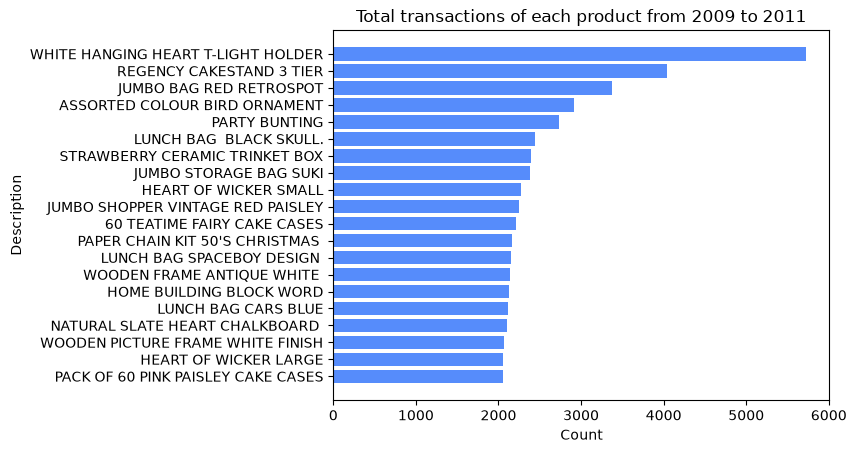

In [57]:
plt.barh(unique_products_value_counts["Description"],unique_products_value_counts["count"])
plt.xlabel("Count")
plt.ylabel("Description")
plt.title("Total transactions of each product from 2009 to 2011")

plt.show()

In [33]:
unique_countries = df_not_canceled['Country'].value_counts().head(10)
unique_countries

Country
United Kingdom    946592
EIRE               17329
Germany            16670
France             13907
Netherlands         5087
Spain               3707
Switzerland         3128
Belgium             3067
Portugal            2550
Australia           1811
Name: count, dtype: int64

In [34]:
unique_products = df_not_canceled['Description'].unique()
print(unique_products)

['15CM CHRISTMAS GLASS BALL 20 LIGHTS' 'PINK CHERRY LIGHTS'
 ' WHITE CHERRY LIGHTS' ... 'SET 10 CARDS SWIRLY XMAS TREE 17104'
 'CREAM HANGING HEART T-LIGHT HOLDER' 'PAPER CRAFT , LITTLE BIRDIE']


In [35]:
df_not_canceled.groupby('Description')['Total Price'].sum().sort_values(ascending=False).head(10)

Description
REGENCY CAKESTAND 3 TIER              344069.30
Manual                                340342.68
DOTCOM POSTAGE                        322657.48
WHITE HANGING HEART T-LIGHT HOLDER    266582.35
PAPER CRAFT , LITTLE BIRDIE           168469.60
JUMBO BAG RED RETROSPOT               150640.27
PARTY BUNTING                         149109.35
ASSORTED COLOUR BIRD ORNAMENT         131817.81
POSTAGE                               127597.42
PAPER CHAIN KIT 50'S CHRISTMAS        123002.89
Name: Total Price, dtype: float64

In [36]:
top_products_by_country = pd.DataFrame(df_not_canceled.groupby(['Country', 'Description'])['Quantity'].sum().sort_values(ascending=False))
top_products_by_country

Quantity
Country        Description                                 
United Kingdom WORLD WAR 2 GLIDERS ASSTD DESIGNS     101113
               WHITE HANGING HEART T-LIGHT HOLDER     88888
               PAPER CRAFT , LITTLE BIRDIE            80995
               MEDIUM CERAMIC TOP STORAGE JAR         77036
               ASSORTED COLOUR BIRD ORNAMENT          75794
...                                                     ...
Japan          MONEY BOX HOUSEKEEPING DESIGN              1
               MONEY BOX FIRST ADE DESIGN                 1
               MONEY BOX CONFECTIONERY DESIGN             1
               MONEY BOX BISCUITS DESIGN                  1
West Indies    WOODLAND PARTY BAG + STICKER SET           1

[30343 rows x 1 columns]

In [37]:
uni_country = df_not_canceled['Country'].nunique()
uni_country

43

In [38]:
#https://stackoverflow.com/questions/60271919/how-to-get-top-5-items-for-each-group-in-grouped-dataframe

top_one_product_each_country = df_not_canceled.groupby(['Country','Description']).agg(sum=('Quantity', 'sum'))

top_one_product_each_country.sort_values('sum',ascending=False).groupby('Country').head(1)

,,sum
Country,Description,
United Kingdom,WORLD WAR 2 GLIDERS ASSTD DESIGNS,101113
Denmark,BLACK AND WHITE PAISLEY FLOWER MUG,25164
France,SET/6 FRUIT SALAD PAPER CUPS,7176
Netherlands,FOLKART ZINC HEART CHRISTMAS DEC,6697
Sweden,MINI HIGHLIGHTER PENS,5760
EIRE,60 TEATIME FAIRY CAKE CASES,5580
Japan,RABBIT NIGHT LIGHT,3408
Australia,MINI PAINT SET VINTAGE,3060
Germany,ROUND SNACK BOXES SET OF4 WOODLAND,2746


In [39]:
df_not_canceled_uk = df_not_canceled[df_not_canceled['Country'] == "United Kingdom"]

df_not_canceled

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day,Total Price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,30.00
...,...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9,12.60
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9,14.85


In [40]:
df_not_canceled_uk.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     101113
WHITE HANGING HEART T-LIGHT HOLDER     88888
PAPER CRAFT , LITTLE BIRDIE            80995
MEDIUM CERAMIC TOP STORAGE JAR         77036
ASSORTED COLOUR BIRD ORNAMENT          75794
JUMBO BAG RED RETROSPOT                72339
BROCADE RING PURSE                     70954
PACK OF 60 PINK PAISLEY CAKE CASES     46302
SMALL POPCORN HOLDER                   45941
60 TEATIME FAIRY CAKE CASES            41538
Name: Quantity, dtype: int64

In [41]:
display(df)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1
...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9


In [42]:
df['Invoice'].dtype

<StringDtype(storage='python', na_value=nan)>

In [43]:
display(df_not_canceled)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day,Total Price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,30.00
...,...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9,12.60
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9,14.85


In [44]:
#https://stackoverflow.com/questions/22342285/summing-two-columns-in-a-pandas-dataframe
df_not_canceled['Month Year'] = (df_not_canceled['InvoiceDate'].dt.month).astype(str) + "-" + (df_not_canceled['InvoiceDate'].dt.year).astype(str)

In [45]:
df_not_canceled

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day,Total Price,Month Year
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,83.40,12-2009
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00,12-2009
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00,12-2009
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,100.80,12-2009
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,30.00,12-2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9,12.60,12-2011
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60,12-2011
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60,12-2011
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9,14.85,12-2011


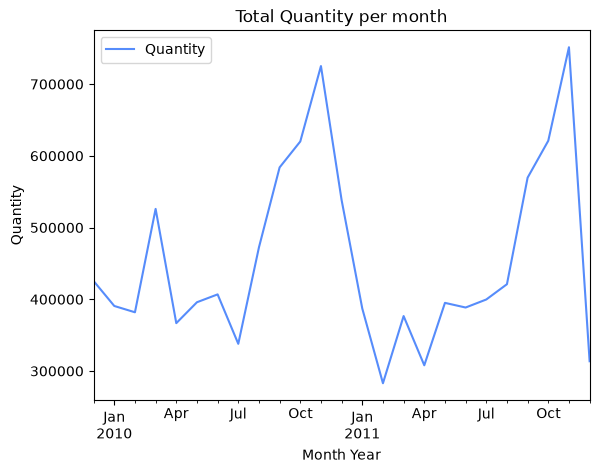

In [58]:
df_not_canceled["Month Year"] = pd.to_datetime(df_not_canceled["Month Year"])
month_year_quantity_group_by = pd.DataFrame(df_not_canceled.groupby("Month Year")["Quantity"].sum()).reset_index()

month_year_quantity_group_by.plot(x="Month Year", y="Quantity", kind="line")
plt.title("Total Quantity per month")
plt.ylabel("Quantity")
plt.show()

In [47]:
df_not_canceled

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year,month,day,Total Price,Month Year
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,83.40,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,81.00,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,100.80,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,30.00,2009-12-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1055233,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011,12,9,12.60,2011-12-01
1055234,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60,2011-12-01
1055235,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011,12,9,16.60,2011-12-01
1055236,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011,12,9,14.85,2011-12-01


In [48]:
uk_percentage = len(df_not_canceled[df_not_canceled['Country'] == "United Kingdom"]) / len(df_not_canceled) * 100
uk_percentage

91.93658982880963